# VHLSS · Preprocess và phân tích thu nhập

Một notebook dùng chung cho nhóm: **thiết lập → preprocess toàn bộ dữ liệu → hàm kiểm định → thu nhập**.

**Colab:** mở notebook, chọn **Runtime → Run all**. Dữ liệu tự tải từ nguồn GitHub cố định; không cần Drive hoặc đường dẫn máy cá nhân. File `processed/vhlss_processed.csv` được tạo lại sau preprocess. Chỉ tải CSV về máy khi cần.

Preprocess giữ đủ **2010, 2012, 2014**. Phần thu nhập dùng **2010 và 2014**, hai mẫu độc lập. Mỗi dòng là một hộ/năm; không có mã hộ để ghép panel.

## 1. Thiết lập chung

CPI **bình quân năm**, cùng gốc 2010 = 100. CI **95% hai phía**; mức ý nghĩa **5%**. Kiểm định có thể một phía theo H₁, nhưng CI trình bày luôn hai phía.

Nguồn CPI: [Niên giám thống kê 2014, bảng 250, trang in 551](https://www.nso.gov.vn/wp-content/uploads/2019/10/Nien-giam-2014-pdf.pdf). Không dùng chỉ số tháng 12 hoặc chỉ số năm trước = 100 để chia trực tiếp giữa hai năm.

In [1]:
# Cài các thư viện còn thiếu; Colab thường có sẵn cả bốn.
import importlib.util
import subprocess
import sys

packages = ["numpy", "pandas", "scipy", "matplotlib"]
missing_packages = [name for name in packages if importlib.util.find_spec(name) is None]
if missing_packages:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing_packages])

from pathlib import Path
from io import BytesIO
from urllib.request import urlopen
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

CONFIDENCE_LEVEL = 0.95
ALPHA = 1 - CONFIDENCE_LEVEL
CPI = {2010: 100.00, 2012: 129.50, 2014: 143.69}
ANALYSIS_YEARS = [2010, 2014]
TOP_FRACTION = 0.001

OUTPUT_DIR = Path.cwd() / "processed"
OUTPUT_DIR.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
display(pd.Series(CPI, name="CPI · 2010 = 100").rename_axis("year").to_frame())

,CPI · 2010 = 100
year,
2010,100.000
2012,129.500
2014,143.690


## 2. Đọc nguồn merged

Nguồn được khóa theo commit và SHA-256 để cả nhóm dùng cùng dữ liệu. Có thể chạy ngoại tuyến bằng cách đặt `SOURCE_PATH` trỏ đến **vhlss_merged.csv gốc** đã tải từ link bên dưới. Không dùng bản clean cũ hoặc CSV processed làm đầu vào.

In [2]:
SOURCE_COMMIT = "4a2c3c06ba191010f536b811deb9e65de6424d46"
SOURCE_URL = (
    "https://raw.githubusercontent.com/letranggaby-cloud/vhlss-project-thong-ke/"
    f"{SOURCE_COMMIT}/processed/vhlss_merged.csv"
)
SOURCE_SHA256 = "3bd8aa79bea915a588ff7340b24020d66369fd6024e5af1f9670fad59b09bd6d"
SOURCE_PATH = None  # Ví dụ: Path("/content/vhlss_merged.csv") nếu chạy bằng file tải lên.

if SOURCE_PATH is None:
    with urlopen(SOURCE_URL, timeout=90) as response:
        source_bytes = response.read()
else:
    source_bytes = Path(SOURCE_PATH).read_bytes()

if hashlib.sha256(source_bytes).hexdigest() != SOURCE_SHA256:
    raise ValueError("Nguồn khác bản đã thống nhất. Kiểm tra file hoặc cập nhật nguồn có chủ đích.")

raw = pd.read_csv(BytesIO(source_bytes))
print(f"Đầu vào: {len(raw):,} dòng × {raw.shape[1]} cột.")
display(raw.head(3))

Đầu vào: 28,196 dòng × 31 cột.


,Year,province,area,size,income,rice,...,tv,emachine,hmachine,Inc_head,Quart,year
0,2010,1,1,6,"146,800.000","4,613.000",...,"16,000.000",500.000,"16,150.000","24,466.667",4,2010
1,2010,1,1,2,"268,300.000","2,358.500",...,"5,000.000",500.000,"34,800.000","134,150.000",4,2010
2,2010,1,1,4,"279,400.000","3,952.500",...,500.000,0.000,"7,200.000","69,850.000",4,2010


## 3. Preprocess toàn bộ biến

- Chuẩn tên cột; gộp `Year/year` khi khớp nhau. Giữ thứ tự dòng và nhãn `Quart` gốc.
- Tiền thiếu/âm/không hữu hạn → thiếu; **0 vẫn là 0**. `size` phải là số nguyên dương. Không tự xóa ngoại lệ hoặc dòng giống nhau vì chưa có mã hộ xác nhận trùng.
- Thu nhập và 13 khoản chi là **nghìn đồng/hộ/năm**. Giá trị nhà, đồ bền là **nghìn đồng/hộ**, không cộng vào chi tiêu.
- Tổng chi 13 khoản chỉ có khi đủ cả 13; tổng 12 không gồm `fuel` là chỉ tiêu đối chiếu. Không điền `fuel` thiếu bằng 0.
- Tài sản > 0: có; = 0: không; thiếu: chưa rõ. Chi điện/nước/rác không đại diện tiếp cận dịch vụ.

Quy đổi tiền: **giá 2010 = tiền danh nghĩa × 100/CPI**. Thu nhập đầu người tính lại từ `income/size`; `income_pc_reported` giữ số đầu người do nguồn cung cấp để đối chiếu.

In [3]:
EXPENSE_COLUMNS = [
    "rice", "nrice", "tobaco", "nfood", "edu", "med", "hins",
    "aid", "water", "elec", "garb", "fuel", "fhouse",
]
ASSET_COLUMNS = [
    "house", "oto", "moto", "bicycle", "bed", "tab", "tele", "tv", "emachine", "hmachine",
]
MONEY_COLUMNS = ["income", *EXPENSE_COLUMNS, *ASSET_COLUMNS]
PROVINCE_CODES = [
    1, 2, 4, 6, 8, 10, 11, 12, 14, 15, 17, 19, 20, 22, 24, 25,
    26, 27, 30, 31, 33, 34, 35, 36, 37, 38, 40, 42, 44, 45, 46,
    48, 49, 51, 52, 54, 56, 58, 60, 62, 64, 66, 67, 68, 70, 72,
    74, 75, 77, 79, 80, 82, 83, 84, 86, 87, 89, 91, 92, 93, 94, 95, 96,
]


def preprocess_vhlss(source):
    """Chuẩn hóa dữ liệu; trả lại bảng sạch và nhật ký theo biến."""
    data = source.copy()
    data.columns = data.columns.str.strip().str.lower()
    data = data.rename(columns={"tabl": "tab", "inc_head": "income_pc_reported"})

    # Nguồn hiện có cả Year và year; chỉ giữ một cột khi hai cột khớp.
    if list(data.columns).count("year") > 1:
        year_columns = data.loc[:, "year"]
        if not year_columns.eq(year_columns.iloc[:, 0], axis=0).all().all():
            raise ValueError("Hai cột năm không khớp.")
        data = data.loc[:, ~data.columns.duplicated()].copy()
    if data.columns.duplicated().any():
        raise ValueError("Còn tên cột bị trùng sau chuẩn hóa.")

    required = ["year", "province", "area", "size", "quart", "income_pc_reported", *MONEY_COLUMNS]
    absent = set(required) - set(data.columns)
    if absent:
        raise ValueError(f"Thiếu cột bắt buộc: {sorted(absent)}")

    audit_rows = []
    for column in required:
        original = data[column]
        numeric = pd.to_numeric(original, errors="coerce")
        finite = numeric.where(np.isfinite(numeric))
        audit_rows.append({
            "variable": column, "missing_input": int(original.isna().sum()),
            "invalid_numeric": int((original.notna() & finite.isna()).sum()),
            "negative": int(finite.lt(0).sum()),
        })
        data[column] = finite

    if data["year"].isna().any() or not data["year"].isin(CPI).all():
        raise ValueError("Có năm thiếu hoặc chưa khai báo CPI.")
    data["year"] = data["year"].astype(int)
    data.insert(0, "source_row", np.arange(len(data)) + 2)  # Dòng trong CSV, không phải mã hộ.
    data.insert(0, "record_id", data["year"].astype(str) + "-" + data["source_row"].astype(str))

    for column, valid_codes in [("province", PROVINCE_CODES), ("area", [1, 2]), ("quart", [1, 2, 3, 4])]:
        data[column] = data[column].where(data[column].isin(valid_codes)).astype("Int64")
    data["size"] = data["size"].where(data["size"].gt(0) & data["size"].mod(1).eq(0))

    amount_columns = [*MONEY_COLUMNS, "income_pc_reported"]
    data["invalid_amount_count"] = data[amount_columns].lt(0).sum(axis=1)
    data[amount_columns] = data[amount_columns].where(data[amount_columns].ge(0))
    data["cpi_2010_100"] = data["year"].map(CPI)
    price_factor = 100 / data["cpi_2010_100"]

    # Tiền theo hộ: nghìn đồng; biến đầu người bên dưới: triệu đồng.
    real_amounts = data[MONEY_COLUMNS].mul(price_factor, axis=0).add_suffix("_real_2010")
    data = pd.concat([data, real_amounts], axis=1)
    data["income_pc_nominal"] = data["income"] / data["size"] / 1000
    data["income_pc_real"] = data["income_pc_nominal"] * price_factor
    data["income_pc_source_mismatch"] = (
        data["income_pc_reported"].notna() & data["income_pc_nominal"].notna()
        & ~np.isclose(data["income_pc_reported"], data["income_pc_nominal"] * 1000)
    )
    data["expense_complete_13"] = data[EXPENSE_COLUMNS].notna().all(axis=1)
    expenses_12 = [column for column in EXPENSE_COLUMNS if column != "fuel"]
    data["expense_complete_12"] = data[expenses_12].notna().all(axis=1)
    data["expense_13_nominal"] = data[EXPENSE_COLUMNS].sum(axis=1, min_count=13)
    data["expense_12_nominal"] = data[expenses_12].sum(axis=1, min_count=12)
    data["expense_13_pc_real"] = data["expense_13_nominal"] / data["size"] / 1000 * price_factor
    data["expense_12_pc_real"] = data["expense_12_nominal"] / data["size"] / 1000 * price_factor
    for column in EXPENSE_COLUMNS:
        data[f"{column}_pc_real"] = data[f"{column}_real_2010"] / data["size"] / 1000
    data["health_pc_real"] = data[["med_pc_real", "hins_pc_real", "aid_pc_real"]].sum(axis=1, min_count=3)
    denominator = data["expense_13_nominal"].where(data["expense_13_nominal"].gt(0))
    data["food_share"] = data[["rice", "nrice"]].sum(axis=1, min_count=2) / denominator
    data["education_share"] = data["edu"] / denominator
    for column in ASSET_COLUMNS:
        data[f"owns_{column}"] = data[column].gt(0).where(data[column].notna()).astype("Int64")
    data["area_label"] = data["area"].map({1: "Thành thị", 2: "Nông thôn"})
    data["quart_label"] = data["quart"].map({q: f"Q{q}" for q in [1, 2, 3, 4]})
    audit = pd.DataFrame(audit_rows).set_index("variable")
    audit["missing_output"] = data[audit.index].isna().sum()
    return data, audit


data, cleaning_audit = preprocess_vhlss(raw)
display(cleaning_audit.loc[cleaning_audit[["missing_input", "invalid_numeric", "negative", "missing_output"]].gt(0).any(axis=1)])

,missing_input,invalid_numeric,negative,missing_output
variable,,,,
nfood,1,0,0,1
fuel,817,0,0,817
fhouse,23,0,0,23
house,23,0,11,34
oto,284,0,0,284
moto,284,0,5,289
bicycle,284,0,3,287
bed,284,0,16,300
tab,284,0,5,289


### Kiểm tra và lưu một bản processed

Không lọc thiếu toàn bảng: mỗi phân tích chỉ bỏ dòng thiếu đúng biến cần dùng. Bảng tỷ lệ thiếu tách theo năm, Quart và khu vực giúp thấy mất mẫu có chọn lọc.

In [4]:
sample_audit = data.groupby("year").agg(
    households=("record_id", "size"), valid_income=("income_pc_real", "count"),
    complete_13=("expense_complete_13", "sum"), complete_12=("expense_complete_12", "sum"),
    income_mismatch=("income_pc_source_mismatch", "sum"),
)
display(sample_audit)

missing_by_group = data.groupby(["year", "quart_label", "area_label"], dropna=False).agg(
    households=("record_id", "size"), missing_fuel_pct=("fuel", lambda x: 100 * x.isna().mean()),
    missing_expense_13_pct=("expense_13_pc_real", lambda x: 100 * x.isna().mean()),
    missing_moto_pct=("owns_moto", lambda x: 100 * x.isna().mean()),
)
display(missing_by_group.round(2))

assert len(data) == len(raw) and data["record_id"].is_unique
assert set(data["year"]) == set(CPI)
assert data.loc[~data["expense_complete_13"], "expense_13_nominal"].isna().all()
assert data[MONEY_COLUMNS].ge(0).where(data[MONEY_COLUMNS].notna(), True).all().all()
assert data.loc[data["year"].eq(2010), "cpi_2010_100"].eq(100).all()

processed_path = OUTPUT_DIR / "vhlss_processed.csv"
data.to_csv(processed_path, index=False)
print(f"Đã lưu {len(data):,} dòng × {data.shape[1]} cột: processed/{processed_path.name}")
print(f"Nguồn có {raw.duplicated().sum()} dòng giống dòng trước; giữ lại vì chưa có mã hộ xác nhận trùng.")

,households,valid_income,complete_13,complete_12,income_mismatch
year,,,,,
2010,9399,9399,9387,9390,0
2012,9399,9399,9391,9391,0
2014,9398,9398,8579,9391,0


households  missing_fuel_pct  \
year quart_label area_label                                 
2010 Q1          Nông thôn         2155             0.000   
                 Thành thị          195             0.000   
     Q2          Nông thôn         1913             0.000   
                 Thành thị          436             0.000   
     Q3          Nông thôn         1584             0.060   
                 Thành thị          766             0.130   
     Q4          Nông thôn         1098             0.000   
                 Thành thị         1252             0.080   
2012 Q1          Nông thôn         2145             0.050   
                 Thành thị          205             0.000   
     Q2          Nông thôn         1893             0.000   
                 Thành thị          456             0.000   
     Q3          Nông thôn         1557             0.000   
                 Thành thị          793             0.000   
     Q4          Nông thôn         1101             0.000   
                 Thành thị         1249             0.000   
2014 Q1          Nông thôn         2144            21.830   
                 Thành thị          208            18.270   
     Q2          Nông thôn         1882             9.090   
                 Thành thị          468             6.200   
     Q3          Nông thôn         1481             4.320   
                 Thành thị          866             1.150   
     Q4          Nông thôn         1110             1.890   
                 Thành thị         1239             0.970   

                             missing_expense_13_pct  missing_moto_pct  
year quart_label area_label                                            
2010 Q1          Nông thôn                    0.140             5.850  
                 Thành thị                    0.510             5.640  
     Q2          Nông thôn                    0.100             0.890  
                 Thành thị                    0.000             1.610  
     Q3          Nông thôn                    0.130             0.510  
                 Thành thị                    0.130             0.650  
     Q4          Nông thôn                    0.180             0.270  
                 Thành thị                    0.080             0.320  
2012 Q1          Nông thôn                    0.140             2.280  
                 Thành thị                    0.000             2.930  
     Q2          Nông thôn                    0.000             0.110  
                 Thành thị                    0.220             0.000  
     Q3          Nông thôn                    0.000             0.320  
                 Thành thị                    0.130             0.000  
     Q4          Nông thôn                    0.090             0.090  
                 Thành thị                    0.160             0.000  
2014 Q1          Nông thôn                   21.880             1.820  
                 Thành thị                   18.270             0.480  
     Q2          Nông thôn                    9.140             0.110  
                 Thành thị                    6.200             0.000  
     Q3          Nông thôn                    4.390             0.140  
                 Thành thị                    1.150             0.000  
     Q4          Nông thôn                    2.160             0.000  
                 Thành thị                    0.970             0.080

Đã lưu 28,196 dòng × 95 cột: processed/vhlss_processed.csv
Nguồn có 9 dòng giống dòng trước; giữ lại vì chưa có mã hộ xác nhận trùng.


### Từ điển dùng nhanh

| Biến / hậu tố | Ý nghĩa và đơn vị |
|---|---|
| `year`, `province`, `area`, `size`, `quart` | Năm, mã tỉnh giai đoạn khảo sát, khu vực, số người, Quart nguồn |
| `income`, 13 biến chi, 10 biến tài sản | Danh nghĩa, nghìn đồng/hộ; thu/chi tính năm, tài sản là giá trị tại khảo sát |
| `*_real_2010` | Giá 2010, nghìn đồng/hộ; CPI chung cũng chỉ là xấp xỉ cho giá trị tài sản |
| `income_pc_nominal` | Triệu đồng/người/năm, giá hiện hành |
| `income_pc_real`, `*_pc_real` | Triệu đồng/người/năm, giá 2010 |
| `expense_13_*`, `expense_12_*` | Tổng đủ 13 khoản; tổng đối chiếu 12 khoản không gồm fuel |
| `health_pc_real` | Tổng `med + hins + aid` đầu người; cần đủ ba khoản |
| `food_share`, `education_share` | Tỷ trọng trong tổng chi đủ 13 khoản; thang 0–1 |
| `owns_*` | 1 có, 0 không, ô trống chưa rõ |
| `source_row`, `record_id` | Truy ngược dòng CSV nguồn; **không phải mã hộ qua các năm** |
| `income_pc_reported` | Thu nhập đầu người nguồn, nghìn đồng/người/năm |

`rice`: gạo; `nrice`: thực phẩm ngoài gạo; `tobaco`: thuốc lá; `nfood`: phi thực phẩm, chưa gồm khoản chi riêng; `edu`: giáo dục; `med`: thuốc; `hins`: bảo hiểm y tế; `aid`: chăm sóc người bệnh; `water/elec/garb/fuel`: nước/điện/rác/nhiên liệu; `fhouse`: sửa nhà.

`house`: nhà; `oto/moto/bicycle`: ô tô/xe máy/xe đạp; `bed/tab`: giường/bàn ghế; `tele/tv`: điện thoại/tivi; `emachine/hmachine`: thiết bị giải trí/gia dụng.

## 4. Bộ hàm kiểm định dùng chung

`x - y` luôn là hướng chênh lệch. `alternative`: `greater` cho H₁ >, `less` cho H₁ <, `two-sided` cho H₁ ≠. H₀ dùng dấu **=**. Các hàm dùng chung `CONFIDENCE_LEVEL` và `ALPHA` ở đầu notebook.

| Nhóm hàm | Kiến thức lớp và điều kiện chính |
|---|---|
| `one_sample_t_test`, `one_sample_z_test` | Chap 6: mean; t khi σ chưa biết, Z khi biết σ tổng thể |
| `paired_t_test` | Chap 7 §7.2.1: hiệu trong cặp thật; cần chuẩn của hiệu hoặc xấp xỉ mean phù hợp |
| `independent_t_test` | Chap 7 §7.2.3–4: hai mẫu độc lập; mặc định Welch, chỉ pooled khi có cơ sở σ₁² = σ₂² |
| `independent_z_test` | Chap 7 §7.2.2: biết cả hai σ tổng thể |
| `variance_test`, `variance_ratio_test` | Chap 6/7 §7.3: χ² một phương sai, F hai phương sai; đòi hỏi tổng thể chuẩn |
| `one_proportion_test`, `two_proportion_test` | Chap 6/7 §7.4: Z tỷ lệ, số thành công/thất bại đủ lớn; hai mẫu độc lập |
| `one_way_anova`, `two_way_anova` | Chap 8: quan sát độc lập, sai số chuẩn và phương sai chung; hàm hai nhân tố chỉ dùng thiết kế cân bằng trong slide |
| `chi_square_gof`, `chi_square_independence` | Chap 9 §9.1–2: tần số đếm, kỳ vọng mỗi ô ≥ 5 |
| `correlation_test` | Chap 7 §7.5/Chap 9 §9.3: Pearson hoặc Spearman; quan sát theo cặp, độc lập giữa các cặp |
| `jarque_bera_test` | Chap 9 §9.4: kiểm tra chuẩn bằng skew/kurtosis, xấp xỉ χ²₂ |

Hàm không tự xác nhận điều kiện thống kê. ANOVA mặc định chỉ trả phân rã SS; chỉ tính p khi người gọi đặt `assumptions_met=True` sau khi đánh giá. Không dùng ANOVA cổ điển cho thu nhập VHLSS chỉ vì đã có hàm.

In [5]:
def numeric_sample(values, minimum=2):
    """Bỏ NaN/inf của một mẫu; báo lỗi khi không đủ dữ liệu."""
    sample = np.asarray(values, dtype=float)
    if sample.ndim != 1:
        raise ValueError("Mẫu phải là mảng một chiều.")
    sample = sample[np.isfinite(sample)]
    if len(sample) < minimum:
        raise ValueError(f"Cần ít nhất {minimum} quan sát hợp lệ.")
    return sample


def paired_samples(x, y, minimum=3):
    """Bỏ thiếu theo cặp, giữ đúng sự tương ứng do người dùng cung cấp."""
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if x.ndim != 1 or y.ndim != 1 or x.shape != y.shape:
        raise ValueError("Hai mẫu phải một chiều và cùng độ dài, đã ghép đúng ID.")
    valid = np.isfinite(x) & np.isfinite(y)
    if valid.sum() < minimum:
        raise ValueError(f"Cần ít nhất {minimum} cặp hợp lệ.")
    return x[valid], y[valid]


def tail_probability(statistic, distribution, alternative):
    if alternative == "greater":
        return float(distribution.sf(statistic))
    if alternative == "less":
        return float(distribution.cdf(statistic))
    if alternative == "two-sided":
        return float(min(1, 2 * min(distribution.cdf(statistic), distribution.sf(statistic))))
    raise ValueError("alternative phải là greater, less hoặc two-sided.")


def test_result(method, statistic, p_value, **details):
    """Cấu trúc kết quả chung; CI có ý nghĩa theo tham số từng hàm."""
    return {"method": method, "statistic": float(statistic), "p_value": float(p_value),
            "reject_h0": bool(p_value < ALPHA), **details}


def mean_test_result(method, estimate, null_value, se, distribution, alternative, **details):
    if not np.isfinite(se) or se <= 0:
        raise ValueError("SE phải dương; kiểm tra mẫu có phương sai bằng 0.")
    statistic = (estimate - null_value) / se
    margin = distribution.ppf(1 - ALPHA / 2) * se
    return test_result(method, statistic, tail_probability(statistic, distribution, alternative),
                       estimate=float(estimate), se=float(se), null_value=null_value,
                       ci_low=float(estimate - margin), ci_high=float(estimate + margin),
                       confidence_level=CONFIDENCE_LEVEL, alternative=alternative, **details)

### 4.1. Mean: t-test và Z-test

Một mẫu: $T=(\bar x-\mu_0)/(s/\sqrt n)$, df = n−1. Mẫu ghép: áp dụng công thức đó lên $d_i=x_i-y_i$.

Hai mẫu độc lập, Welch: $SE=\sqrt{s_x^2/n_x+s_y^2/n_y}$; $\nu=(a+b)^2/[a^2/(n_x-1)+b^2/(n_y-1)]$, với $a=s_x^2/n_x$, $b=s_y^2/n_y$. Bản pooled dùng $s_p^2=[(n_x-1)s_x^2+(n_y-1)s_y^2]/(n_x+n_y-2)$.

CI chênh lệch mean: $(\bar x-\bar y)\pm t_{\nu;0,975}SE$. Z thay phương sai mẫu bằng **phương sai tổng thể đã biết**, dùng chuẩn tắc và mốc 0,975.

In [6]:
def one_sample_t_test(x, mu0=0, alternative="two-sided"):
    x = numeric_sample(x)
    return mean_test_result("One-sample t", x.mean(), mu0, x.std(ddof=1) / np.sqrt(len(x)),
                            stats.t(len(x) - 1), alternative, n=len(x), df=len(x) - 1)


def paired_t_test(x, y, difference0=0, alternative="two-sided"):
    """Chỉ dùng khi x[i], y[i] là cùng đối tượng đã ghép đúng mã."""
    x, y = paired_samples(x, y, minimum=2)
    result = one_sample_t_test(x - y, difference0, alternative)
    return {**result, "method": "Paired t"}


def independent_t_test(x, y, difference0=0, alternative="two-sided", equal_var=False):
    x, y = numeric_sample(x), numeric_sample(y)
    nx, ny = len(x), len(y)
    vx, vy = x.var(ddof=1), y.var(ddof=1)
    if equal_var:
        df = nx + ny - 2
        pooled_variance = ((nx - 1) * vx + (ny - 1) * vy) / df
        se = np.sqrt(pooled_variance * (1 / nx + 1 / ny))
    else:
        a, b = vx / nx, vy / ny
        if a + b <= 0:
            raise ValueError("Không tính được Welch khi cả hai phương sai bằng 0.")
        se = np.sqrt(a + b)
        df = (a + b)**2 / (a**2 / (nx - 1) + b**2 / (ny - 1))
    return mean_test_result("Pooled t" if equal_var else "Welch t", x.mean() - y.mean(),
                            difference0, se, stats.t(df), alternative, df=df,
                            n_x=nx, n_y=ny, mean_x=x.mean(), mean_y=y.mean())


def one_sample_z_test(x, sigma, mu0=0, alternative="two-sided"):
    x = numeric_sample(x)
    if not np.isfinite(sigma) or sigma <= 0:
        raise ValueError("sigma tổng thể phải dương.")
    return mean_test_result("One-sample Z", x.mean(), mu0, sigma / np.sqrt(len(x)),
                            stats.norm(), alternative, n=len(x))


def independent_z_test(x, y, sigma_x, sigma_y, difference0=0, alternative="two-sided"):
    x, y = numeric_sample(x), numeric_sample(y)
    if not np.isfinite([sigma_x, sigma_y]).all() or min(sigma_x, sigma_y) <= 0:
        raise ValueError("Cả hai sigma tổng thể phải dương.")
    se = np.sqrt(sigma_x**2 / len(x) + sigma_y**2 / len(y))
    return mean_test_result("Independent Z", x.mean() - y.mean(), difference0, se,
                            stats.norm(), alternative, n_x=len(x), n_y=len(y))

### 4.2. Phương sai và tỷ lệ

Chuẩn: $Q=(n-1)s^2/\sigma_0^2\sim\chi^2_{n-1}$; hai mẫu chuẩn độc lập: $F=(s_x^2/s_y^2)/r_0\sim F_{n_x-1,n_y-1}$. CI của phương sai hoặc tỷ số dùng các phân vị χ²/F tương ứng.

Tỷ lệ: $Z=(\hat p-p_0)/\sqrt{p_0(1-p_0)/n}$. Hai mẫu, H₀: $p_x=p_y$, dùng tỷ lệ gộp trong SE kiểm định; CI chênh lệch dùng SE không gộp. CI tỷ lệ ở đây là **xấp xỉ Wald trong lớp**.

In [7]:
def variance_test(x, variance0, alternative="two-sided", *, normal_population=False):
    if not normal_population:
        raise ValueError("Kiểm định này cần tổng thể chuẩn; xác nhận normal_population=True khi có cơ sở.")
    x = numeric_sample(x)
    if not np.isfinite(variance0) or variance0 <= 0 or x.var(ddof=1) <= 0:
        raise ValueError("Phương sai giả thuyết và phương sai mẫu phải dương.")
    df = len(x) - 1
    numerator = df * x.var(ddof=1)
    statistic = numerator / variance0
    return test_result("Variance chi-square", statistic,
                       tail_probability(statistic, stats.chi2(df), alternative),
                       estimate=x.var(ddof=1), df=df,
                       ci_low=numerator / stats.chi2.ppf(1 - ALPHA / 2, df),
                       ci_high=numerator / stats.chi2.ppf(ALPHA / 2, df),
                       confidence_level=CONFIDENCE_LEVEL)


def variance_ratio_test(x, y, ratio0=1, alternative="two-sided", *, normal_population=False):
    if not normal_population:
        raise ValueError("F-test cần hai tổng thể chuẩn độc lập; xác nhận normal_population=True khi có cơ sở.")
    x, y = numeric_sample(x), numeric_sample(y)
    if not np.isfinite(ratio0) or ratio0 <= 0 or min(x.var(ddof=1), y.var(ddof=1)) <= 0:
        raise ValueError("Tỷ số giả thuyết và hai phương sai mẫu phải dương.")
    ratio = x.var(ddof=1) / y.var(ddof=1)
    distribution = stats.f(len(x) - 1, len(y) - 1)
    return test_result("Variance ratio F", ratio / ratio0,
                       tail_probability(ratio / ratio0, distribution, alternative), estimate=ratio,
                       df1=len(x) - 1, df2=len(y) - 1,
                       ci_low=ratio / distribution.ppf(1 - ALPHA / 2),
                       ci_high=ratio / distribution.ppf(ALPHA / 2), confidence_level=CONFIDENCE_LEVEL)


def validate_counts(successes, n):
    if not np.isfinite([successes, n]).all() or n <= 0 or n != int(n):
        raise ValueError("n phải là số nguyên dương.")
    if successes != int(successes) or not 0 <= successes <= n:
        raise ValueError("Số thành công phải nguyên và nằm trong [0, n].")


def one_proportion_test(successes, n, p0, alternative="two-sided"):
    validate_counts(successes, n)
    if not 0 < p0 < 1 or min(n * p0, n * (1 - p0), successes, n - successes) < 5:
        raise ValueError("Chưa đủ số thành công/thất bại cho Z và CI Wald; không dùng xấp xỉ này.")
    estimate = successes / n
    se_null = np.sqrt(p0 * (1 - p0) / n)
    statistic = (estimate - p0) / se_null
    margin = stats.norm.ppf(1 - ALPHA / 2) * np.sqrt(estimate * (1 - estimate) / n)
    return test_result("One-proportion Z", statistic,
                       tail_probability(statistic, stats.norm(), alternative), estimate=estimate,
                       ci_low=estimate - margin, ci_high=estimate + margin,
                       confidence_level=CONFIDENCE_LEVEL, n=n)


def two_proportion_test(success_x, n_x, success_y, n_y, alternative="two-sided"):
    """H0: p_x - p_y = 0; mỗi success/n tính trên các dòng đã biết trạng thái."""
    validate_counts(success_x, n_x)
    validate_counts(success_y, n_y)
    if min(success_x, n_x - success_x, success_y, n_y - success_y) < 5:
        raise ValueError("Mỗi mẫu cần ít nhất 5 thành công và 5 thất bại.")
    px, py = success_x / n_x, success_y / n_y
    pooled = (success_x + success_y) / (n_x + n_y)
    se_null = np.sqrt(pooled * (1 - pooled) * (1 / n_x + 1 / n_y))
    statistic = (px - py) / se_null
    se_ci = np.sqrt(px * (1 - px) / n_x + py * (1 - py) / n_y)
    margin = stats.norm.ppf(1 - ALPHA / 2) * se_ci
    return test_result("Two-proportion Z", statistic,
                       tail_probability(statistic, stats.norm(), alternative), estimate=px - py,
                       ci_low=px - py - margin, ci_high=px - py + margin,
                       confidence_level=CONFIDENCE_LEVEL, n_x=n_x, n_y=n_y)

### 4.3. ANOVA: có bảng SS, df, MS, F

Một nhân tố: $SS_B=\sum n_g(\bar y_g-\bar y)^2$; $SS_W=\sum_g\sum_i(y_{ig}-\bar y_g)^2$. $F=MS_B/MS_W$; dưới điều kiện ANOVA, $F\sim F_{k-1,N-k}$.

Hai nhân tố: dữ liệu **cân bằng**, mỗi ô có cùng số quan sát; phân rã $SS_T=SS_A+SS_B+SS_{AB}+SS_E$. Với mô hình không tương tác, $SS_{AB}$ được đưa vào phần dư theo giả định cộng tính. Thiết kế không cân bằng sẽ báo lỗi để tránh áp dụng sai công thức slide.

In [8]:
def one_way_anova(groups, *, assumptions_met=False):
    """groups: dict tên nhóm -> mảng số. Mặc định chỉ mô tả SS."""
    samples = {name: numeric_sample(values) for name, values in groups.items()}
    if len(samples) < 2:
        raise ValueError("ANOVA cần ít nhất hai nhóm.")
    sizes = np.array([len(x) for x in samples.values()])
    means = np.array([x.mean() for x in samples.values()])
    grand_mean = np.average(means, weights=sizes)
    ss_between = np.sum(sizes * (means - grand_mean)**2)
    ss_within = sum(np.sum((x - x.mean())**2) for x in samples.values())
    df_between, df_within = len(samples) - 1, sizes.sum() - len(samples)
    ms_between, ms_within = ss_between / df_between, ss_within / df_within
    if ms_within <= 0:
        raise ValueError("Phương sai trong nhóm phải dương.")
    f_ratio = ms_between / ms_within
    table = pd.DataFrame({
        "SS": [ss_between, ss_within, ss_between + ss_within],
        "df": [df_between, df_within, sizes.sum() - 1],
        "MS": [ms_between, ms_within, np.nan], "F_ratio": [f_ratio, np.nan, np.nan],
    }, index=["Between", "Within", "Total"])
    table["p_value"] = np.nan
    if assumptions_met:
        table.loc["Between", "p_value"] = stats.f.sf(f_ratio, df_between, df_within)
    table["interpretation"] = "Kiểm định có điều kiện" if assumptions_met else "Chỉ phân rã SS"
    return table


def two_way_anova(frame, value, factor_a, factor_b, *, interaction=True, assumptions_met=False):
    """ANOVA hai nhân tố cân bằng theo Chap 8; không dùng cho ô VHLSS không cân bằng."""
    clean = frame[[value, factor_a, factor_b]].dropna().copy()
    clean = clean.loc[np.isfinite(clean[value])]
    a_levels = clean[factor_a].unique()
    b_levels = clean[factor_b].unique()
    if min(len(a_levels), len(b_levels)) < 2:
        raise ValueError("Mỗi nhân tố cần ít nhất hai mức.")
    counts = clean.groupby([factor_a, factor_b], observed=True).size()
    if len(counts) != len(a_levels) * len(b_levels) or counts.nunique() != 1:
        raise ValueError("Thiết kế không cân bằng hoặc thiếu ô; không áp dụng công thức này.")
    a, b, r = len(a_levels), len(b_levels), int(counts.iloc[0])
    if interaction and r < 2:
        raise ValueError("Cần ít nhất hai quan sát mỗi ô để kiểm định tương tác.")
    grand = clean[value].mean()
    mean_a = clean.groupby(factor_a, observed=True)[value].mean()
    mean_b = clean.groupby(factor_b, observed=True)[value].mean()
    mean_cell = clean.groupby([factor_a, factor_b], observed=True)[value].mean()
    ss_a = b * r * ((mean_a - grand)**2).sum()
    ss_b = a * r * ((mean_b - grand)**2).sum()
    ss_ab = r * sum((m - mean_a.loc[i] - mean_b.loc[j] + grand)**2
                    for (i, j), m in mean_cell.items())
    cell_fitted = np.array([mean_cell.loc[(i, j)] for i, j in zip(clean[factor_a], clean[factor_b])])
    ss_error = np.sum((clean[value].to_numpy() - cell_fitted)**2)
    effects = {str(factor_a): (ss_a, a - 1), str(factor_b): (ss_b, b - 1)}
    if interaction:
        effects["Interaction"] = (ss_ab, (a - 1) * (b - 1))
        df_error = a * b * (r - 1)
    else:
        ss_error += ss_ab
        df_error = len(clean) - a - b + 1
    ms_error = ss_error / df_error
    if ms_error <= 0:
        raise ValueError("MS phần dư phải dương.")
    rows = []
    for name, (ss, df) in effects.items():
        f_ratio = (ss / df) / ms_error
        rows.append({"source": name, "SS": ss, "df": df, "MS": ss / df,
                     "F_ratio": f_ratio,
                     "p_value": stats.f.sf(f_ratio, df, df_error) if assumptions_met else np.nan})
    rows.extend([
        {"source": "Error", "SS": ss_error, "df": df_error, "MS": ms_error},
        {"source": "Total", "SS": ((clean[value] - grand)**2).sum(), "df": len(clean) - 1},
    ])
    table = pd.DataFrame(rows).set_index("source")
    table["interpretation"] = "Kiểm định có điều kiện" if assumptions_met else "Chỉ phân rã SS"
    return table

### 4.4. χ², tương quan và chuẩn

χ²: $Q=\sum(O-E)^2/E$; df = k−1−m cho goodness of fit (m tham số đã ước lượng), hoặc (r−1)(c−1) cho độc lập. Không tự gộp ô kỳ vọng thấp.

Pearson: $T=r\sqrt{(n-2)/(1-r^2)}$, df = n−2; kiểm định chính xác cần mô hình chuẩn hai biến. Spearman tính Pearson trên hạng, p dùng xấp xỉ mẫu lớn của SciPy; không dùng như kiểm định mean.

Jarque–Bera: $JB=n[skew^2/6+(kurtosis-3)^2/24]\approx\chi^2_2$. Bác bỏ chuẩn không tự đổi tham số mean thành median và không tự xác nhận hay bác bỏ xấp xỉ CLT.

In [9]:
def chi_square_gof(observed, probabilities, estimated_parameters=0):
    observed = np.asarray(observed, dtype=float)
    probabilities = np.asarray(probabilities, dtype=float)
    if observed.ndim != 1 or observed.shape != probabilities.shape or len(observed) < 2:
        raise ValueError("Hai vector cùng độ dài, ít nhất hai nhóm.")
    if (not np.isfinite(observed).all() or not np.isfinite(probabilities).all()
            or (observed < 0).any() or not np.equal(observed, np.floor(observed)).all()
            or (probabilities <= 0).any() or not np.isclose(probabilities.sum(), 1)):
        raise ValueError("Cần tần số nguyên không âm và xác suất dương có tổng bằng 1.")
    if estimated_parameters < 0 or estimated_parameters != int(estimated_parameters):
        raise ValueError("Số tham số ước lượng phải nguyên không âm.")
    expected = observed.sum() * probabilities
    df = len(observed) - 1 - estimated_parameters
    if (expected < 5).any() or df <= 0:
        raise ValueError("Cần mọi kỳ vọng >= 5 và df dương.")
    statistic = np.sum((observed - expected)**2 / expected)
    return test_result("Chi-square GOF", statistic, stats.chi2.sf(statistic, df), df=df,
                       observed=observed, expected=expected)


def chi_square_independence(count_table):
    table = np.asarray(count_table, dtype=float)
    if (table.ndim != 2 or min(table.shape) < 2 or not np.isfinite(table).all()
            or (table < 0).any() or not np.equal(table, np.floor(table)).all()
            or (table.sum(axis=0) == 0).any() or (table.sum(axis=1) == 0).any()):
        raise ValueError("Cần bảng đếm ít nhất 2×2, không có hàng/cột tổng bằng 0.")
    result = stats.chi2_contingency(table, correction=False)
    if (result.expected_freq < 5).any():
        raise ValueError("Có ô kỳ vọng < 5; chưa dùng xấp xỉ chi-square này.")
    return test_result("Chi-square independence", result.statistic, result.pvalue,
                       df=result.dof, expected=result.expected_freq)


def correlation_test(x, y, method="pearson", alternative="two-sided"):
    x, y = paired_samples(x, y)
    if x.var() == 0 or y.var() == 0:
        raise ValueError("Không tính tương quan cho biến hằng.")
    if method == "pearson":
        result = stats.pearsonr(x, y, alternative=alternative)
    elif method == "spearman":
        result = stats.spearmanr(x, y, alternative=alternative)
    else:
        raise ValueError("method phải là pearson hoặc spearman.")
    return test_result(method.title() + " correlation", result.statistic, result.pvalue, n=len(x))


def jarque_bera_test(x):
    x = numeric_sample(x, minimum=3)
    if x.var() <= 0:
        raise ValueError("Jarque–Bera không xác định cho biến hằng.")
    result = stats.jarque_bera(x)
    return test_result("Jarque–Bera", result.statistic, result.pvalue, n=len(x), df=2,
                       skewness=stats.skew(x), excess_kurtosis=stats.kurtosis(x))

### Cách gọi hàm

Ví dụ: `independent_t_test(mau_2014, mau_2010, alternative="greater")` kiểm định mean 2014 lớn hơn 2010. Với dữ liệu có cặp thật đã ghép đúng mã: `paired_t_test(after, before)`.

ANOVA: `one_way_anova({"A": nhom_a, "B": nhom_b, "C": nhom_c})` trả bảng phân rã SS. Chỉ thêm `assumptions_met=True` khi có cơ sở dùng phân phối F. Những hàm này được định nghĩa để dùng lại; phần dưới chỉ gọi hàm phù hợp với bài thu nhập.

## 5. Thu nhập · câu hỏi và mẫu phân tích

1. Thu nhập thực bình quân đầu người có tăng trên toàn mẫu không?
2. Mức tăng trong từng Q1–Q4 và CI 95% là bao nhiêu?
3. Mức tăng trong thành thị, nông thôn và CI 95% là bao nhiêu?

$Y=(income/size)\times(100/CPI)/1000$, đơn vị **triệu đồng/người/năm, giá 2010**. Mean là trung bình Y của các hộ, mỗi hộ có trọng số bằng nhau; chưa phải trung bình dân số có trọng số người.

Với mỗi nhóm g, $\Delta_g=\mu_{g,2014}-\mu_{g,2010}$; estimator là $\bar Y_{g,2014}-\bar Y_{g,2010}$. **H₀: Δg = 0; H₁: Δg > 0**. Dùng t hai mẫu độc lập, phương sai chưa biết/không giả sử bằng nhau, **Chap 7 §7.2.4**. Thống kê $T=\widehat\Delta_g/SE\approx t_\nu$ dưới H₀; p phía phải. CI 95% hai phía của **chênh lệch mean**.

Hai bản: toàn mẫu hợp lệ và bỏ đúng $\lceil0,001n\rceil$ hộ thu nhập cao nhất **trong toàn năm trước khi chia nhóm**. Nhãn Q giữ nguyên. Bản lọc chỉ là đối chiếu độ nhạy; ngưỡng do mẫu xác định nên t/CI thông thường chỉ là xấp xỉ có điều kiện trên bộ lọc, không tính đầy đủ bất định chọn ngưỡng.

In [10]:
income_data = data.loc[
    data["year"].isin(ANALYSIS_YEARS) & data["income_pc_real"].notna(),
    ["record_id", "source_row", "year", "area", "quart", "income_pc_real"],
].copy()

income_samples = {}
removed_rows = []
for year, frame in income_data.groupby("year", sort=True):
    ordered = frame.sort_values(["income_pc_real", "source_row"], ascending=[False, True])
    k = int(np.ceil(TOP_FRACTION * len(ordered)))
    removed_rows.append(ordered.head(k))
    income_samples[("Toàn mẫu", year)] = frame
    income_samples[("Bỏ top 0,1%", year)] = ordered.iloc[k:]

removed_income = pd.concat(removed_rows, ignore_index=True)
display(income_data.groupby("year")["income_pc_real"].agg(["count", "mean", "median", "max"]))
display(removed_income.groupby(["year", "quart"]).size().rename("Số hộ top 0,1%").to_frame())

,count,mean,median,max
year,,,,
2010,9399,18.257,13.168,"2,885.183"
2014,9398,20.861,16.431,698.378


,,"Số hộ top 0,1%"
year,quart,
2010,4,10
2014,4,10


### 5.1. Phân phối Q4 trước khi lọc

Trục tuyến tính giữ rõ độ lớn của đuôi; histogram dùng trục log để thấy vùng tập trung. Log chỉ dùng khi vẽ, kiểm định dùng Y ban đầu. Quan sát cao không tự được coi là lỗi.

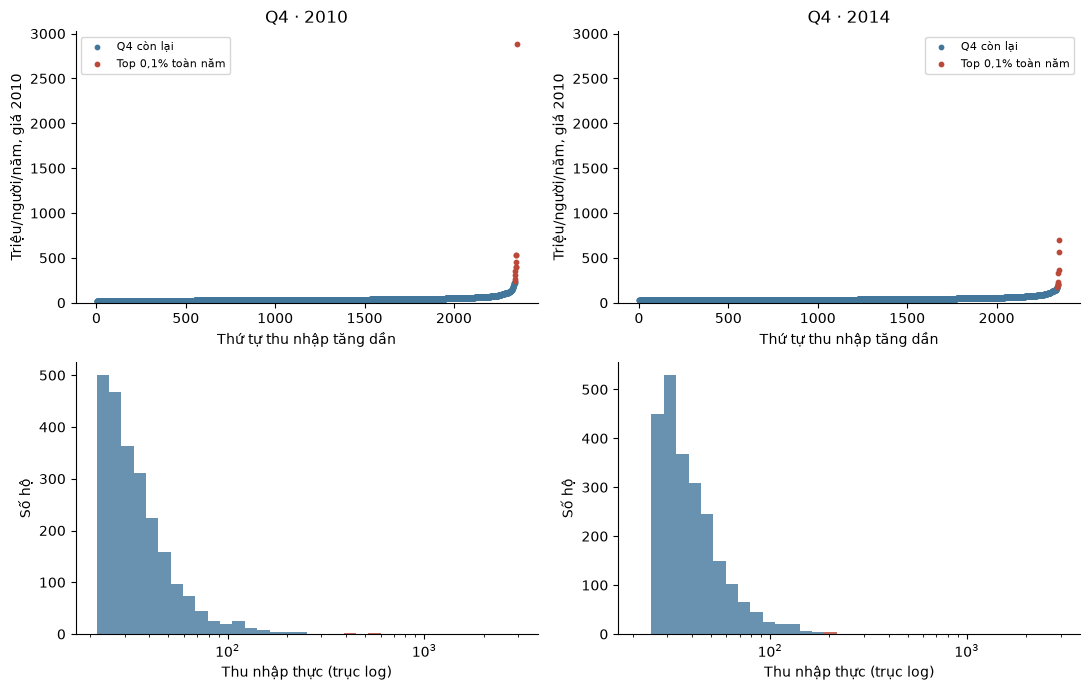

,year,mean,median,top_ss_pct,zero_income_not_on_log
0,2010,40.293,30.928,89.303,0
1,2014,43.390,35.876,53.630,0


In [11]:
figure, axes = plt.subplots(2, 2, figsize=(11, 7))
q4_data = income_data.loc[income_data["quart"].eq(4)]
positive_income = q4_data.loc[q4_data["income_pc_real"].gt(0), "income_pc_real"]
bins = np.geomspace(positive_income.min() * 0.98, positive_income.max() * 1.02, 35)
q4_description = []

for column, year in enumerate(ANALYSIS_YEARS):
    frame = q4_data.loc[q4_data["year"].eq(year)].sort_values("income_pc_real")
    values = frame["income_pc_real"].to_numpy()
    top_mask = frame["record_id"].isin(removed_income["record_id"]).to_numpy()
    ranks = np.arange(1, len(frame) + 1)
    for mask, color, label in [(~top_mask, "#42779b", "Q4 còn lại"),
                               (top_mask, "#bb4939", "Top 0,1% toàn năm")]:
        axes[0, column].scatter(ranks[mask], values[mask], s=10, color=color, label=label)
        axes[1, column].hist(values[mask & (values > 0)], bins=bins, color=color, alpha=0.8)
    axes[0, column].set(title=f"Q4 · {year}", xlabel="Thứ tự thu nhập tăng dần",
                        ylabel="Triệu/người/năm, giá 2010", ylim=(0, q4_data["income_pc_real"].max() * 1.05))
    axes[0, column].legend(fontsize=8)
    axes[1, column].set(xscale="log", xlabel="Thu nhập thực (trục log)", ylabel="Số hộ")
    squared_deviations = (values - values.mean())**2
    q4_description.append({"year": year, "mean": values.mean(), "median": np.median(values),
                           "top_ss_pct": 100 * squared_deviations[top_mask].sum() / squared_deviations.sum(),
                           "zero_income_not_on_log": int((values == 0).sum())})
figure.tight_layout()
plt.show()
display(pd.DataFrame(q4_description).round(3))

### 5.2. Chẩn đoán đúng các mẫu sẽ dùng

Xem n, mean, median, skewness, Jarque–Bera và tỷ phần SS do quan sát lớn nhất trong **từng năm × nhóm × bản mẫu**. Jarque–Bera kiểm tra phân phối Y; không kiểm tra trực tiếp phân phối của mean. Đuôi rất lớn có thể làm xấp xỉ t kém ổn định dù n lớn.

In [12]:
GROUP_FILTERS = {
    "Toàn mẫu": (None, None),
    "Q1": ("quart", 1), "Q2": ("quart", 2), "Q3": ("quart", 3), "Q4": ("quart", 4),
    "Thành thị": ("area", 1), "Nông thôn": ("area", 2),
}


def income_group(frame, group):
    column, value = GROUP_FILTERS[group]
    selected = frame if column is None else frame.loc[frame[column].eq(value).fillna(False)]
    return selected["income_pc_real"].dropna().to_numpy()


diagnostic_rows = []
for (version, year), frame in income_samples.items():
    for group in GROUP_FILTERS:
        values = income_group(frame, group)
        jb = jarque_bera_test(values)
        squared_deviations = (values - values.mean())**2
        diagnostic_rows.append({
            "sample": version, "year": year, "group": group, "n": len(values),
            "mean": values.mean(), "median": np.median(values), "skewness": jb["skewness"],
            "jb_p": jb["p_value"], "reject_normality": jb["reject_h0"],
            "largest_ss_pct": 100 * squared_deviations.max() / squared_deviations.sum(),
        })
income_diagnostics = pd.DataFrame(diagnostic_rows)
for version in ["Toàn mẫu", "Bỏ top 0,1%"]:
    display(Markdown(f"**{version}**"))
    display(income_diagnostics.loc[income_diagnostics["sample"].eq(version)].drop(columns="sample").round(3))

**Toàn mẫu**

,year,group,n,mean,median,skewness,jb_p,reject_normality,largest_ss_pct
0,2010,Toàn mẫu,9399,18.257,13.168,56.001,0.000,True,67.987
1,2010,Q1,2350,5.257,5.383,-0.334,0.000,True,0.366
2,2010,Q2,2349,10.382,10.336,0.053,0.000,True,0.143
3,2010,Q3,2350,17.093,16.781,0.252,0.000,True,0.155
4,2010,Q4,2350,40.293,30.928,34.200,0.000,True,78.007
5,2010,Thành thị,2649,27.089,21.115,5.704,0.000,True,7.578
6,2010,Nông thôn,6750,14.791,11.020,62.570,0.000,True,82.430
14,2014,Toàn mẫu,9398,20.861,16.431,9.126,0.000,True,11.977
15,2014,Q1,2352,6.292,6.390,-0.215,0.000,True,0.309
16,2014,Q2,2350,13.024,12.989,0.043,0.000,True,0.130


**Bỏ top 0,1%**

,year,group,n,mean,median,skewness,jb_p,reject_normality,largest_ss_pct
7,2010,Toàn mẫu,9389,17.598,13.152,4.045,0.000,True,1.873
8,2010,Q1,2350,5.257,5.383,-0.334,0.000,True,0.366
9,2010,Q2,2349,10.382,10.336,0.053,0.000,True,0.143
10,2010,Q3,2350,17.093,16.781,0.252,0.000,True,0.155
11,2010,Q4,2340,37.744,30.826,3.827,0.000,True,3.600
12,2010,Thành thị,2643,26.406,21.093,3.332,0.000,True,3.546
13,2010,Nông thôn,6746,14.147,11.012,4.497,0.000,True,4.300
21,2014,Toàn mẫu,9388,20.543,16.424,2.760,0.000,True,0.909
22,2014,Q1,2352,6.292,6.390,-0.215,0.000,True,0.309
23,2014,Q2,2350,13.024,12.989,0.043,0.000,True,0.130


### 5.3. Tính một lần bằng hàm chung

Truyền năm 2014 vào `x`, năm 2010 vào `y` để chênh lệch luôn là **2014 − 2010**. Các p/CI áp dụng riêng từng so sánh, chưa bảo đảm đồng thời cho mọi nhóm.

In [13]:
result_rows = []
for version in ["Toàn mẫu", "Bỏ top 0,1%"]:
    for group in GROUP_FILTERS:
        earlier = income_group(income_samples[(version, 2010)], group)
        later = income_group(income_samples[(version, 2014)], group)
        test = independent_t_test(later, earlier, alternative="greater")
        result_rows.append({
            "sample": version, "group": group, "n_2010": len(earlier), "n_2014": len(later),
            "mean_2010": earlier.mean(), "mean_2014": later.mean(),
            "growth_pct": 100 * test["estimate"] / earlier.mean(), **test,
        })
income_results = pd.DataFrame(result_rows)


def show_income_results(groups):
    """Bảng ngắn cho bài; income_results giữ đủ SE, t, df, p và CI."""
    selected = income_results.loc[income_results["group"].isin(groups)]
    for version in ["Toàn mẫu", "Bỏ top 0,1%"]:
        table = selected.loc[selected["sample"].eq(version)].copy()
        table["CI 95%"] = [f"[{low:.3f}; {high:.3f}]" for low, high in zip(table["ci_low"], table["ci_high"])]
        table["Kết luận 5%"] = np.where(table["reject_h0"], "Bác bỏ H₀", "Không bác bỏ H₀")
        table = table[["group", "mean_2010", "mean_2014", "estimate", "growth_pct", "CI 95%", "p_value", "Kết luận 5%"]]
        table = table.rename(columns={"group": "Nhóm", "mean_2010": "Mean 2010", "mean_2014": "Mean 2014",
                                      "estimate": "Mức tăng", "growth_pct": "Tăng (%)", "p_value": "p phía phải"})
        display(Markdown(f"**{version}** · triệu đồng/người/năm, giá 2010"))
        display(table.style.hide(axis="index").format({
            "Mean 2010": "{:.3f}", "Mean 2014": "{:.3f}", "Mức tăng": "{:.3f}",
            "Tăng (%)": "{:.2f}", "p phía phải": "{:.3e}",
        }))

### Câu 1 · Thu nhập thực bình quân toàn mẫu có tăng không?

H₀: μ2014 − μ2010 = 0; H₁: μ2014 − μ2010 > 0. Mean của toàn mẫu hợp lệ từng năm; Welch t phía phải, CI 95% hai phía.

In [14]:
show_income_results(["Toàn mẫu"])
for row in income_results.loc[income_results["group"].eq("Toàn mẫu")].itertuples():
    evidence = "có bằng chứng mean tăng" if row.reject_h0 else "chưa đủ bằng chứng mean tăng"
    display(Markdown(
        f"**{row.sample}:** tăng ước lượng **{row.estimate:.3f} triệu/người/năm ({row.growth_pct:.2f}%)**, "
        f"CI 95% **[{row.ci_low:.3f}; {row.ci_high:.3f}]**; {evidence} theo kiểm định xấp xỉ."
    ))

**Toàn mẫu** · triệu đồng/người/năm, giá 2010

Nhóm,Mean 2010,Mean 2014,Mức tăng,Tăng (%),CI 95%,p phía phải,Kết luận 5%
Toàn mẫu,18.257,20.861,2.604,14.26,[1.771; 3.436],4.445e-10,Bác bỏ H₀


**Bỏ top 0,1%** · triệu đồng/người/năm, giá 2010

Nhóm,Mean 2010,Mean 2014,Mức tăng,Tăng (%),CI 95%,p phía phải,Kết luận 5%
Toàn mẫu,17.598,20.543,2.944,16.73,[2.468; 3.421],5.617e-34,Bác bỏ H₀


**Toàn mẫu:** tăng ước lượng **2.604 triệu/người/năm (14.26%)**, CI 95% **[1.771; 3.436]**; có bằng chứng mean tăng theo kiểm định xấp xỉ.

**Bỏ top 0,1%:** tăng ước lượng **2.944 triệu/người/năm (16.73%)**, CI 95% **[2.468; 3.421]**; có bằng chứng mean tăng theo kiểm định xấp xỉ.

### Câu 2 · Mức tăng trong Q1–Q4

Với từng q: H₀: μq,2014 − μq,2010 = 0; H₁: μq,2014 − μq,2010 > 0. Welch t phía phải cho từng Q; CI 95% của chênh lệch mean. Nhãn Q là nhóm của từng năm, không theo dõi cùng hộ.

In [15]:
show_income_results(["Q1", "Q2", "Q3", "Q4"])
q1 = income_results.loc[income_results["sample"].eq("Toàn mẫu") & income_results["group"].eq("Q1")].iloc[0]
display(Markdown(
    f"Q1 tăng ước lượng **{q1['estimate']:.3f} triệu/người/năm**, tương đương "
    f"**{q1['estimate'] * 1000 / 12:.0f} nghìn/người/tháng** theo giá 2010. "
    "Đọc Q4 cùng chẩn đoán đuôi trên và bản lọc. Không suy nhóm nào tăng nhanh hơn chỉ từ p của từng nhóm."
))

**Toàn mẫu** · triệu đồng/người/năm, giá 2010

Nhóm,Mean 2010,Mean 2014,Mức tăng,Tăng (%),CI 95%,p phía phải,Kết luận 5%
Q1,5.257,6.292,1.035,19.69,[0.931; 1.139],3.043e-81,Bác bỏ H₀
Q2,10.382,13.024,2.642,25.45,[2.542; 2.742],0.000e+00,Bác bỏ H₀
Q3,17.093,20.758,3.665,21.44,[3.514; 3.816],0.000e+00,Bác bỏ H₀
Q4,40.293,43.390,3.097,7.69,[0.166; 6.029],1.919e-02,Bác bỏ H₀


**Bỏ top 0,1%** · triệu đồng/người/năm, giá 2010

Nhóm,Mean 2010,Mean 2014,Mức tăng,Tăng (%),CI 95%,p phía phải,Kết luận 5%
Q1,5.257,6.292,1.035,19.69,[0.931; 1.139],3.043e-81,Bác bỏ H₀
Q2,10.382,13.024,2.642,25.45,[2.542; 2.742],0.000e+00,Bác bỏ H₀
Q3,17.093,20.758,3.665,21.44,[3.514; 3.816],0.000e+00,Bác bỏ H₀
Q4,37.744,42.210,4.467,11.83,[3.281; 5.652],8.931e-14,Bác bỏ H₀


Q1 tăng ước lượng **1.035 triệu/người/năm**, tương đương **86 nghìn/người/tháng** theo giá 2010. Đọc Q4 cùng chẩn đoán đuôi trên và bản lọc. Không suy nhóm nào tăng nhanh hơn chỉ từ p của từng nhóm.

### Câu 3 · Mức tăng tại thành thị và nông thôn

Với mỗi khu vực a: H₀: μa,2014 − μa,2010 = 0; H₁: μa,2014 − μa,2010 > 0. So sánh cùng khu vực giữa hai mẫu năm; Welch t phía phải, CI 95%. Chưa kiểm định chênh lệch mức tăng giữa hai khu vực.

In [16]:
show_income_results(["Thành thị", "Nông thôn"])

**Toàn mẫu** · triệu đồng/người/năm, giá 2010

Nhóm,Mean 2010,Mean 2014,Mức tăng,Tăng (%),CI 95%,p phía phải,Kết luận 5%
Thành thị,27.089,29.532,2.444,9.02,[1.110; 3.778],1.662e-04,Bác bỏ H₀
Nông thôn,14.791,17.216,2.425,16.39,[1.418; 3.432],1.193e-06,Bác bỏ H₀


**Bỏ top 0,1%** · triệu đồng/người/năm, giá 2010

Nhóm,Mean 2010,Mean 2014,Mức tăng,Tăng (%),CI 95%,p phía phải,Kết luận 5%
Thành thị,26.406,28.965,2.559,9.69,[1.458; 3.661],2.681e-06,Bác bỏ H₀
Nông thôn,14.147,17.008,2.861,20.22,[2.412; 3.310],6.962e-36,Bác bỏ H₀


### 5.4. Nhìn chung các mức tăng và CI 95%

Mỗi khoảng là CI riêng của chênh lệch mean 2014 − 2010. Đường 0 làm mốc đối chiếu; CI hai phía không tương đương hoàn toàn với kiểm định một phía mức 5%.

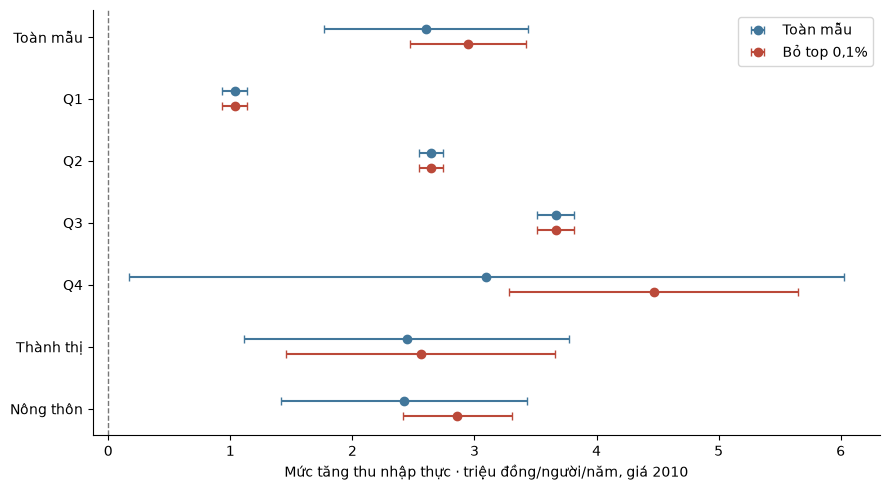

In [17]:
figure, axis = plt.subplots(figsize=(9, 5))
groups = list(GROUP_FILTERS)
for version, offset, color in [("Toàn mẫu", -0.12, "#42779b"), ("Bỏ top 0,1%", 0.12, "#bb4939")]:
    rows = income_results.loc[income_results["sample"].eq(version)].set_index("group").loc[groups]
    axis.errorbar(rows["estimate"], np.arange(len(groups)) + offset,
                  xerr=[rows["estimate"] - rows["ci_low"], rows["ci_high"] - rows["estimate"]],
                  fmt="o", capsize=3, color=color, label=version)
axis.axvline(0, color="#777777", linestyle="--", linewidth=1)
axis.set(yticks=np.arange(len(groups)), yticklabels=groups,
         xlabel="Mức tăng thu nhập thực · triệu đồng/người/năm, giá 2010")
axis.invert_yaxis()
axis.legend()
figure.tight_layout()
plt.show()

### Nhận xét và phạm vi kết luận

Nguồn lực thu nhập bình quân tăng theo giá chung nếu ước lượng và kiểm định trên hỗ trợ; không có nghĩa mọi hộ đều tăng hoặc cùng hộ đã cải thiện qua thời gian. Q1 giúp xem cải thiện có xuất hiện ở đáy phân phối; Q4 cần đọc cùng độ nhạy với đuôi trên.

Các kết quả chưa xét trọng số, tầng/cụm khảo sát, giá vùng hoặc bất định của nhãn Quart. CPI chung là xấp xỉ sức mua. Bản lọc không chứng minh quan sát cao là sai và thay đổi phạm vi hộ được mô tả. Phân tích thu nhập chưa đủ để kết luận về nợ, tích lũy, chất lượng giáo dục/y tế hoặc mức sống toàn diện.

## 6. Đối chiếu kết quả và dùng lại

Kiểm tra 14 phép Welch với SciPy, số dòng và bộ lọc. Kết quả và biểu đồ nằm trong notebook; mặc định không tạo thêm CSV kết quả hoặc ảnh rời.

Teammate mở notebook và Run all để có `data` cùng các hàm kiểm định. Nếu chỉ cần phân tích tiếp, đọc `processed/vhlss_processed.csv`; chú ý đơn vị trong từ điển. Khi đọc lại CSV, `owns_*` có ô trống cần giữ là thiếu.

In [18]:
for row in income_results.itertuples():
    earlier = income_group(income_samples[(row.sample, 2010)], row.group)
    later = income_group(income_samples[(row.sample, 2014)], row.group)
    reference = stats.ttest_ind(later, earlier, equal_var=False, alternative="greater")
    interval = stats.ttest_ind(later, earlier, equal_var=False).confidence_interval(CONFIDENCE_LEVEL)
    np.testing.assert_allclose([row.statistic, row.df], [reference.statistic, reference.df])
    np.testing.assert_allclose(row.p_value, reference.pvalue, rtol=1e-10, atol=0)
    np.testing.assert_allclose([row.ci_low, row.ci_high], [interval.low, interval.high])

for year in ANALYSIS_YEARS:
    original = income_samples[("Toàn mẫu", year)]
    retained = income_samples[("Bỏ top 0,1%", year)]
    removed = removed_income.loc[removed_income["year"].eq(year)]
    assert len(removed) == int(np.ceil(TOP_FRACTION * len(original)))
    assert set(retained["record_id"]).isdisjoint(removed["record_id"])
    assert len(retained) + len(removed) == len(original)
    for group in ["Q1", "Q2", "Q3"]:
        np.testing.assert_allclose(np.sort(income_group(original, group)), np.sort(income_group(retained, group)))

assert len(income_results) == 14
saved = pd.read_csv(processed_path)
assert saved.shape == data.shape
print("Đã đối chiếu 14 Welch t-test và CI 95%; lưu đúng một CSV processed.")

Đã đối chiếu 14 Welch t-test và CI 95%; lưu đúng một CSV processed.
